# TelemetrySentry: Infrastructure Telemetry Anomaly Detection
### Unsupervised Machine Learning with Isolation Forest & Calibrated Decision Boundaries

**TelemetrySentry** is an intelligent monitoring system designed to detect subtle, complex, and catastrophic infrastructure anomalies in high-throughput cloud environments. Unlike traditional static threshold rules (e.g., `CPU > 85%`), TelemetrySentry evaluates the joint multidimensional density of server telemetry across:
- **Request Duration** (`request_duration_ms`)
- **CPU Utilization** (`cpu_usage_pct`)
- **Memory Utilization** (`memory_usage_pct`)
- **Requests Per Second** (`requests_per_second`)
- **Error Rate** (`error_rate_pct`)

---
### Workflow Architecture
1. **Exploratory Data Analysis (EDA)** & distribution analysis of server telemetry
2. **Baseline Isolation Forest** training & decision score evaluation
3. **Threshold Tuning** vs Classical Static Heuristics
4. **Hard Incident Injection Experiment**: Detecting correlated multi-metric anomalies
5. **Threshold Calibration via Validation F1-Score**
6. **Model Artifact Export** for real-time FastAPI inference and Streamlit dashboarding

## 1. Environment Setup & Data Ingestion
We load the historical server telemetry dataset generated with realistic cyclical workloads, noise, and injected operational incidents (CPU spikes, latency spikes, error bursts, and traffic surges).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
)

# Load dataset
df = pd.read_csv("data/telemetry_data.csv")

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nAnomaly distribution:")
print(df["is_anomaly"].value_counts())

Dataset shape: (10000, 8)

First five rows:


,timestamp,request_duration_ms,cpu_usage_pct,memory_usage_pct,requests_per_second,error_rate_pct,is_anomaly,incident_type
0,2026-01-01 00:00:00,184.52,38.93,40.45,85.67,0.33,0,normal
1,2026-01-01 00:00:10,181.92,37.02,47.17,62.43,0.01,0,normal
2,2026-01-01 00:00:20,176.26,29.74,45.57,93.49,0.80,0,normal
3,2026-01-01 00:00:30,206.33,39.06,44.07,96.84,1.72,0,normal
4,2026-01-01 00:00:40,152.93,31.83,43.12,46.76,0.48,0,normal



Column data types:
timestamp                  str
request_duration_ms    float64
cpu_usage_pct          float64
memory_usage_pct       float64
requests_per_second    float64
error_rate_pct         float64
is_anomaly               int64
incident_type              str
dtype: object

Missing values:
timestamp              0
request_duration_ms    0
cpu_usage_pct          0
memory_usage_pct       0
requests_per_second    0
error_rate_pct         0
is_anomaly             0
incident_type          0
dtype: int64

Anomaly distribution:
is_anomaly
0    9600
1     400
Name: count, dtype: int64


## 2. Telemetry Distribution & Anomaly Proportions
We inspect the balance between normal operating periods and operational incident windows.

In [2]:
print(df["is_anomaly"].value_counts())

print("\nAnomaly percentages:")
print((df["is_anomaly"].value_counts(normalize=True) * 100).round(2))

is_anomaly
0    9600
1     400
Name: count, dtype: int64

Anomaly percentages:
is_anomaly
0    96.0
1     4.0
Name: proportion, dtype: float64


## 3. Metric Profiles Over Time
Visualizing all five server telemetry signals across time steps highlights normal baseline trends alongside acute incident spikes.

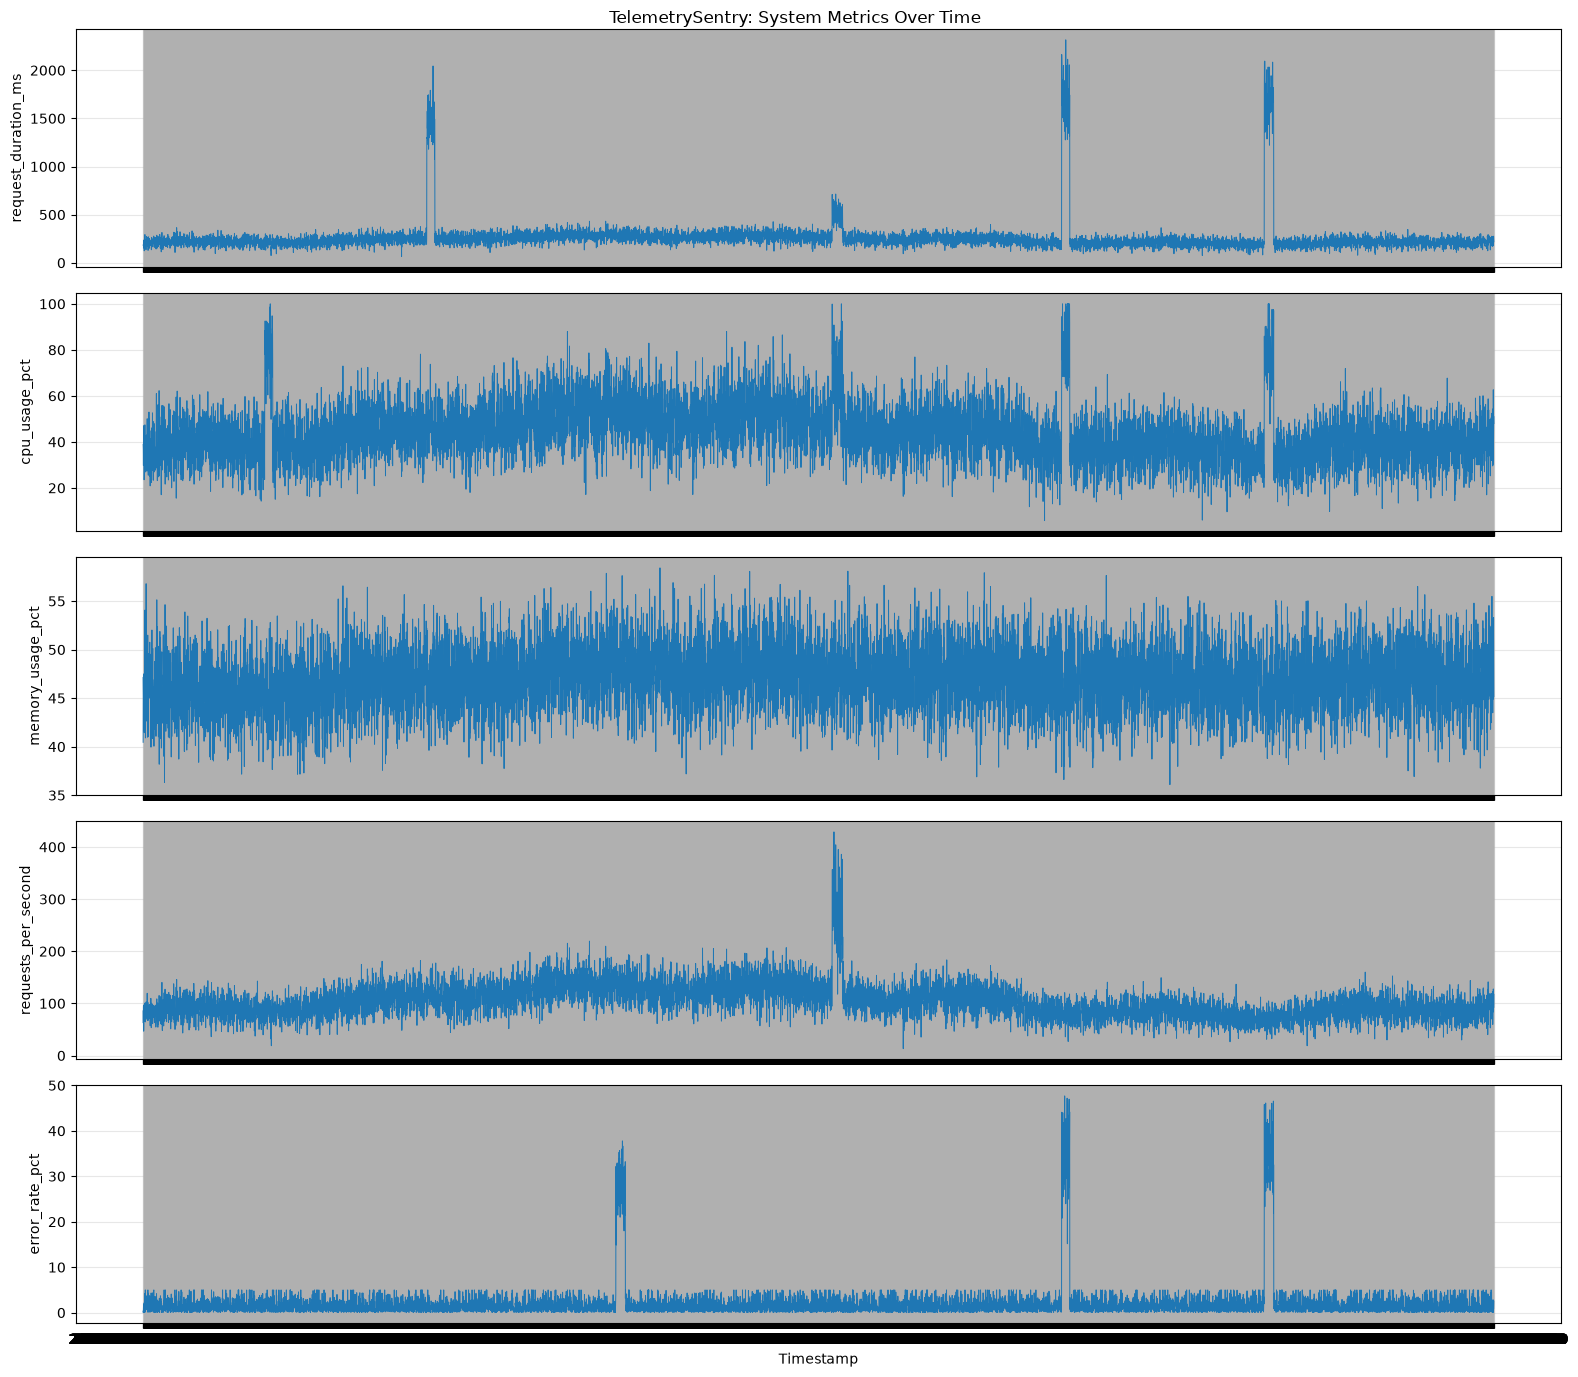

In [3]:
metrics = [
    "request_duration_ms",
    "cpu_usage_pct",
    "memory_usage_pct",
    "requests_per_second",
    "error_rate_pct",
]

fig, axes = plt.subplots(5, 1, figsize=(16, 14), sharex=True)

for ax, metric in zip(axes, metrics):
    ax.plot(df["timestamp"], df[metric], linewidth=0.7)
    ax.set_ylabel(metric)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Timestamp")
fig.suptitle("TelemetrySentry: System Metrics Over Time")
plt.tight_layout()
plt.show()

## 4. Comparing Normal vs Incident Metrics
Summary statistics comparing normal operations with incident conditions.

In [4]:
normal = df[df["is_anomaly"] == 0]
anomalies = df[df["is_anomaly"] == 1]

print("Normal records:", len(normal))
print("Anomaly records:", len(anomalies))

comparison = df.groupby("is_anomaly")[metrics].mean().T
comparison.columns = ["Normal", "Anomaly"]

display(comparison.round(2))

Normal records: 9600
Anomaly records: 400


,Normal,Anomaly
request_duration_ms,236.65,949.12
cpu_usage_pct,42.91,67.72
memory_usage_pct,47.06,46.74
requests_per_second,102.61,133.78
error_rate_pct,1.45,16.98


## 5. Feature Matrix & Train/Test Split
We split the dataset chronologically (70% training, 30% testing) to respect temporal ordering.

In [5]:
features = [
    "request_duration_ms",
    "cpu_usage_pct",
    "memory_usage_pct",
    "requests_per_second",
    "error_rate_pct",
]

X = df[features].copy()
y_true = df["is_anomaly"].copy()

print("Feature matrix shape:", X.shape)
print("Ground-truth labels shape:", y_true.shape)

display(X.head())

Feature matrix shape: (10000, 5)
Ground-truth labels shape: (10000,)


,request_duration_ms,cpu_usage_pct,memory_usage_pct,requests_per_second,error_rate_pct
0,184.52,38.93,40.45,85.67,0.33
1,181.92,37.02,47.17,62.43,0.01
2,176.26,29.74,45.57,93.49,0.80
3,206.33,39.06,44.07,96.84,1.72
4,152.93,31.83,43.12,46.76,0.48


In [6]:
split_index = int(len(df) * 0.70)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y_true.iloc[:split_index].copy()
y_test = y_true.iloc[split_index:].copy()

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining anomaly count:", y_train.sum())
print("Testing anomaly count:", y_test.sum())

Training records: 7000
Testing records: 3000

Training anomaly count: 330
Testing anomaly count: 70


## 6. Training the Baseline Isolation Forest Model
Isolation Forest isolates anomalies by randomly selecting a feature and split value. Anomalous points are isolated at shallow depths in tree structures.

In [7]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42
)

model.fit(X_train)

print("Isolation Forest training completed!")

Isolation Forest training completed!


## 7. Baseline Model Predictions & Evaluation

In [8]:
predictions = model.predict(X_test)

# Isolation Forest returns: 1 = normal, -1 = anomaly
y_pred = (predictions == -1).astype(int)

print("Predictions generated!")
print("Total test records:", len(y_pred))
print("Predicted anomalies:", y_pred.sum())
print("Predicted normal records:", (y_pred == 0).sum())

Predictions generated!
Total test records: 3000
Predicted anomalies: 273
Predicted normal records: 2727


              precision    recall  f1-score   support

      Normal       1.00      0.93      0.96      2930
     Anomaly       0.26      1.00      0.41        70

    accuracy                           0.93      3000
   macro avg       0.63      0.97      0.69      3000
weighted avg       0.98      0.93      0.95      3000



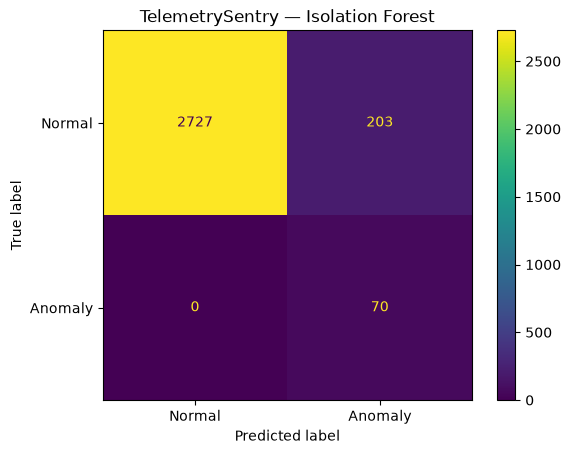

In [9]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Anomaly"]
)

disp.plot()
plt.title("TelemetrySentry — Isolation Forest")
plt.show()

## 8. Decision Function Score Distributions
Lower scores represent isolated, anomalous observations; higher positive scores indicate normal profiles.

In [10]:
scores = model.decision_function(X_test)

results = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": y_pred,
    "anomaly_score": scores,
})

display(results.sort_values("anomaly_score").head(10))

,actual,predicted,anomaly_score
1317,1,1,-0.285449
1367,1,1,-0.282758
1329,1,1,-0.281699
1300,1,1,-0.280912
1310,1,1,-0.279329
1355,1,1,-0.279323
1333,1,1,-0.277185
1364,1,1,-0.276993
1328,1,1,-0.276691
1357,1,1,-0.276659


In [11]:
print("Mean score for normal records:",
      results.loc[results["actual"] == 0, "anomaly_score"].mean().round(4))

print("Mean score for anomalous records:",
      results.loc[results["actual"] == 1, "anomaly_score"].mean().round(4))

Mean score for normal records: 0.0817
Mean score for anomalous records: -0.2625


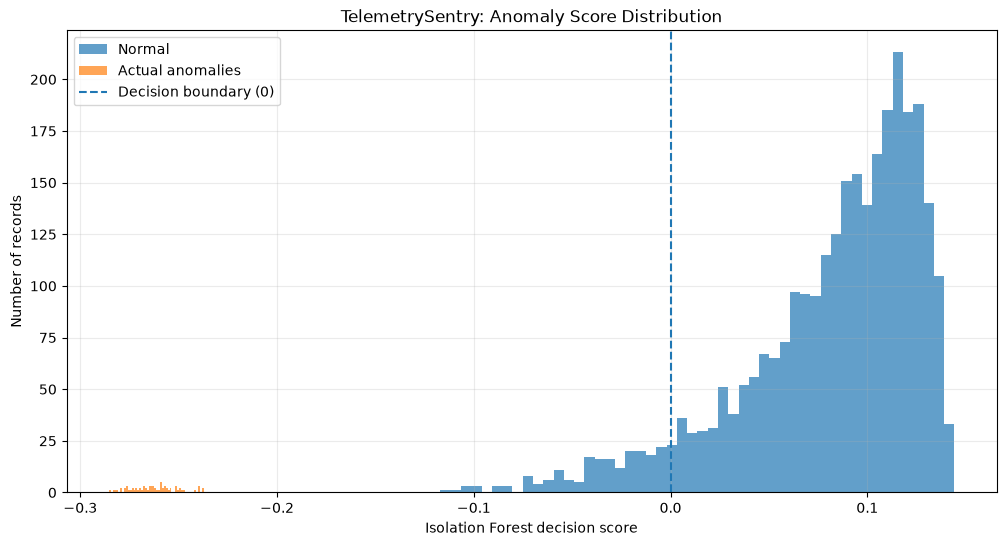

In [12]:
plt.figure(figsize=(12, 6))

plt.hist(
    results.loc[results["actual"] == 0, "anomaly_score"],
    bins=50,
    alpha=0.7,
    label="Normal",
)

plt.hist(
    results.loc[results["actual"] == 1, "anomaly_score"],
    bins=50,
    alpha=0.7,
    label="Actual anomalies",
)

plt.axvline(
    0,
    linestyle="--",
    label="Decision boundary (0)",
)

plt.xlabel("Isolation Forest decision score")
plt.ylabel("Number of records")
plt.title("TelemetrySentry: Anomaly Score Distribution")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 9. Baseline Threshold Tuning
Testing fixed decision boundaries to analyze precision-recall tradeoffs.

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [-0.20, -0.15, -0.10, -0.05, 0.00]

rows = []

for threshold in thresholds:
    predictions_at_threshold = (
        results["anomaly_score"] < threshold
    ).astype(int)

    rows.append({
        "threshold": threshold,
        "precision": precision_score(
            results["actual"], predictions_at_threshold,
            zero_division=0
        ),
        "recall": recall_score(
            results["actual"], predictions_at_threshold,
            zero_division=0
        ),
        "f1_score": f1_score(
            results["actual"], predictions_at_threshold,
            zero_division=0
        ),
        "false_positives": (
            (results["actual"] == 0) &
            (predictions_at_threshold == 1)
        ).sum(),
    })

threshold_results = pd.DataFrame(rows)
display(threshold_results.round(3))

,threshold,precision,recall,f1_score,false_positives
0,-0.20,1.000,1.0,1.000,0
1,-0.15,1.000,1.0,1.000,0
2,-0.10,0.909,1.0,0.952,7
3,-0.05,0.593,1.0,0.745,48
4,0.00,0.256,1.0,0.408,203


              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      2930
     Anomaly       1.00      1.00      1.00        70

    accuracy                           1.00      3000
   macro avg       1.00      1.00      1.00      3000
weighted avg       1.00      1.00      1.00      3000



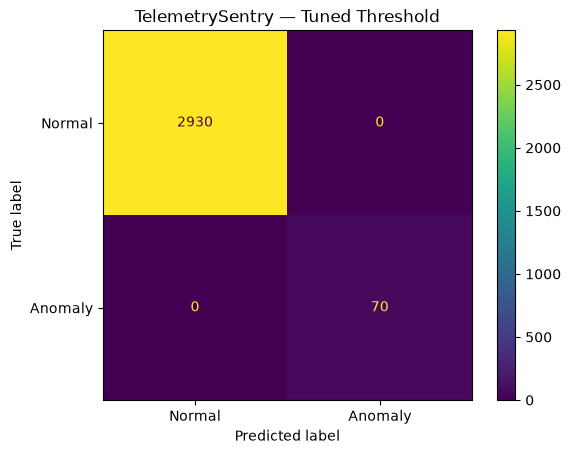

In [14]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

THRESHOLD = -0.15

y_pred_tuned = (model.decision_function(X_test) < THRESHOLD).astype(int)

print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred_tuned)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Anomaly"]
).plot()

plt.title("TelemetrySentry — Tuned Threshold")
plt.show()

## 10. Benchmarking Against Static Rule-Based Thresholds
Static rules (e.g. `request_duration_ms > 1000`, `cpu_usage_pct > 85%`) represent legacy monitoring setups.

In [15]:
rule_pred = (
    (X_test["request_duration_ms"] > 1000) |
    (X_test["cpu_usage_pct"] > 85) |
    (X_test["memory_usage_pct"] > 90) |
    (X_test["error_rate_pct"] > 10) |
    (X_test["requests_per_second"] > 250)
).astype(int)

print("Rule-based anomalies detected:", rule_pred.sum())

print("\nRule-based baseline:")
print(classification_report(
    y_test,
    rule_pred,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

Rule-based anomalies detected: 70

Rule-based baseline:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      2930
     Anomaly       1.00      1.00      1.00        70

    accuracy                           1.00      3000
   macro avg       1.00      1.00      1.00      3000
weighted avg       1.00      1.00      1.00      3000



In [16]:
from sklearn.metrics import precision_score, recall_score, f1_score

comparison = pd.DataFrame({
    "Approach": [
        "Rule-based baseline",
        "Isolation Forest (threshold -0.15)"
    ],
    "Precision": [
        precision_score(y_test, rule_pred, zero_division=0),
        precision_score(y_test, y_pred_tuned, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, rule_pred, zero_division=0),
        recall_score(y_test, y_pred_tuned, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, rule_pred, zero_division=0),
        f1_score(y_test, y_pred_tuned, zero_division=0)
    ]
})

display(comparison.round(3))

,Approach,Precision,Recall,F1-score
0,Rule-based baseline,1.0,1.0,1.0
1,Isolation Forest (threshold -0.15),1.0,1.0,1.0


In [17]:
metric_summary = df.groupby("is_anomaly")[features].agg(
    ["mean", "median", "min", "max"]
)

display(metric_summary.round(2))

request_duration_ms                         cpu_usage_pct         \
                          mean  median    min      max          mean median   
is_anomaly                                                                    
0                       236.65  234.90  64.47   431.98         42.91  42.46   
1                       949.12  602.55  75.29  2315.99         67.72  68.72   

                         memory_usage_pct                       \
              min    max             mean median    min    max   
is_anomaly                                                       
0            5.79   88.0            47.06  47.07  36.09  58.42   
1           31.84  100.0            46.74  46.74  36.61  57.62   

           requests_per_second                        error_rate_pct         \
                          mean  median    min     max           mean median   
is_anomaly                                                                    
0                       102.61  100.20  13.26  219.41           1.45   1.09   
1                       133.78  105.02  18.89  428.85          16.98   9.93   

                         
             min    max  
is_anomaly               
0           0.00   5.00  
1           0.02  47.68

In [18]:
rules = {
    "High latency": X_test["request_duration_ms"] > 1000,
    "High CPU": X_test["cpu_usage_pct"] > 85,
    "High memory": X_test["memory_usage_pct"] > 90,
    "High error rate": X_test["error_rate_pct"] > 10,
    "High traffic": X_test["requests_per_second"] > 250,
}

for name, condition in rules.items():
    detected = ((condition) & (y_test.to_numpy() == 1)).sum()
    false_alarms = ((condition) & (y_test.to_numpy() == 0)).sum()

    print(
        f"{name:15} | "
        f"Detected anomalies: {detected:3} | "
        f"False alarms: {false_alarms:3}"
    )

High latency    | Detected anomalies:  70 | False alarms:   0
High CPU        | Detected anomalies:  19 | False alarms:   0
High memory     | Detected anomalies:   0 | False alarms:   0
High error rate | Detected anomalies:  70 | False alarms:   0
High traffic    | Detected anomalies:   0 | False alarms:   0


In [19]:
for metric in features:
    normal_values = df.loc[df["is_anomaly"] == 0, metric]
    anomaly_values = df.loc[df["is_anomaly"] == 1, metric]

    print(f"\n{metric}")
    print(f"  Normal median:  {normal_values.median():.2f}")
    print(f"  Anomaly median: {anomaly_values.median():.2f}")
    print(f"  Normal 95th percentile: {normal_values.quantile(0.95):.2f}")
    print(f"  Anomaly 5th percentile: {anomaly_values.quantile(0.05):.2f}")


request_duration_ms
  Normal median:  234.91
  Anomaly median: 602.55
  Normal 95th percentile: 323.57
  Anomaly 5th percentile: 193.30

cpu_usage_pct
  Normal median:  42.47
  Anomaly median: 68.72
  Normal 95th percentile: 61.76
  Anomaly 5th percentile: 39.82

memory_usage_pct
  Normal median:  47.07
  Anomaly median: 46.74
  Normal 95th percentile: 52.36
  Anomaly 5th percentile: 40.75

requests_per_second
  Normal median:  100.19
  Anomaly median: 105.02
  Normal 95th percentile: 153.26
  Anomaly 5th percentile: 50.87

error_rate_pct
  Normal median:  1.09
  Anomaly median: 9.93
  Normal 95th percentile: 4.12
  Anomaly 5th percentile: 0.25


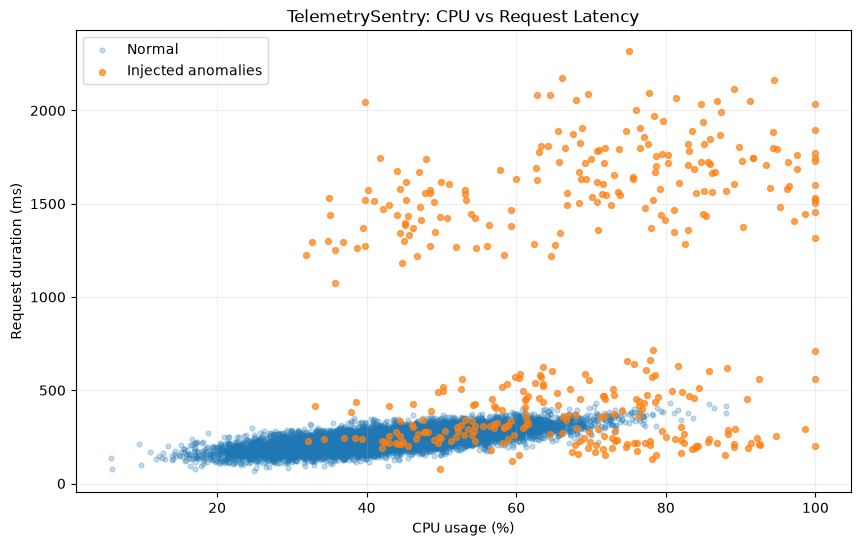

In [20]:
plt.figure(figsize=(10, 6))

normal_mask = df["is_anomaly"] == 0
anomaly_mask = df["is_anomaly"] == 1

plt.scatter(
    df.loc[normal_mask, "cpu_usage_pct"],
    df.loc[normal_mask, "request_duration_ms"],
    alpha=0.25,
    s=12,
    label="Normal",
)

plt.scatter(
    df.loc[anomaly_mask, "cpu_usage_pct"],
    df.loc[anomaly_mask, "request_duration_ms"],
    alpha=0.7,
    s=18,
    label="Injected anomalies",
)

plt.xlabel("CPU usage (%)")
plt.ylabel("Request duration (ms)")
plt.title("TelemetrySentry: CPU vs Request Latency")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 11. Subtle Multi-Metric Incident Injection Experiment
In this experiment, we inject subtle correlated deviations where CPU increases by +10%, latency increases by +100ms, and error rate increases by +4%.
No individual metric breaches static thresholds, making this a challenging test for multidimensional ML anomaly detection.

In [21]:
df_hard = df.copy()
rng = np.random.default_rng(123)

candidate_rows = df_hard.index[
    (df_hard["is_anomaly"] == 0) &
    (df_hard["cpu_usage_pct"].between(40, 60)) &
    (df_hard["request_duration_ms"].between(200, 350)) &
    (df_hard["error_rate_pct"] < 3)
].to_numpy()

selected_rows = rng.choice(
    candidate_rows,
    size=100,
    replace=False
)

df_hard.loc[selected_rows, "cpu_usage_pct"] += 10
df_hard.loc[selected_rows, "request_duration_ms"] += 100
df_hard.loc[selected_rows, "error_rate_pct"] += 4

df_hard.loc[selected_rows, "is_anomaly"] = 1
df_hard.loc[selected_rows, "incident_type"] = "subtle_correlated_incident"

print("Original dataset rows:", len(df))
print("Experimental dataset rows:", len(df_hard))
print("New subtle incidents:", len(selected_rows))
print("\nUpdated label counts:")
print(df_hard["is_anomaly"].value_counts())

Original dataset rows: 10000
Experimental dataset rows: 10000
New subtle incidents: 100

Updated label counts:
is_anomaly
0    9500
1     500
Name: count, dtype: int64


## 12. Train / Validation / Test Splitting for Boundary Calibration
We establish a 60% Train / 20% Validation / 20% Test partition to tune our decision threshold on unseen validation data before final evaluation.

In [22]:
features = [
    "request_duration_ms",
    "cpu_usage_pct",
    "memory_usage_pct",
    "requests_per_second",
    "error_rate_pct",
]

X_hard = df_hard[features].copy()
y_hard = df_hard["is_anomaly"].copy()

train_end = int(len(df_hard) * 0.60)
val_end = int(len(df_hard) * 0.80)

X_train_hard = X_hard.iloc[:train_end]
y_train_hard = y_hard.iloc[:train_end]

X_val_hard = X_hard.iloc[train_end:val_end]
y_val_hard = y_hard.iloc[train_end:val_end]

X_test_hard = X_hard.iloc[val_end:]
y_test_hard = y_hard.iloc[val_end:]

print("Training rows:", len(X_train_hard))
print("Training anomalies:", y_train_hard.sum())

print("\nValidation rows:", len(X_val_hard))
print("Validation anomalies:", y_val_hard.sum())

print("\nTest rows:", len(X_test_hard))
print("Test anomalies:", y_test_hard.sum())

Training rows: 6000
Training anomalies: 339

Validation rows: 2000
Validation anomalies: 79

Test rows: 2000
Test anomalies: 82


In [23]:
from sklearn.ensemble import IsolationForest

hard_model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42
)

hard_model.fit(X_train_hard)

print("Fresh Isolation Forest trained!")

Fresh Isolation Forest trained!


In [24]:
from sklearn.metrics import precision_score, recall_score, f1_score

val_scores = hard_model.decision_function(X_val_hard)

print("Validation score range:",
      round(val_scores.min(), 4), "to", round(val_scores.max(), 4))

print("Validation anomaly count:", int(y_val_hard.sum()))

Validation score range: -0.3036 to 0.1438
Validation anomaly count: 79


## 13. Threshold Optimization on Validation Set
We scan candidate thresholds to find the decision boundary maximizing the F1-score.

In [25]:
thresholds = np.unique(
    np.quantile(val_scores, np.linspace(0.01, 0.30, 100))
)

val_results = []

for threshold in thresholds:
    val_pred = (val_scores < threshold).astype(int)

    val_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val_hard, val_pred, zero_division=0
        ),
        "recall": recall_score(
            y_val_hard, val_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_val_hard, val_pred, zero_division=0
        ),
    })

val_results = pd.DataFrame(val_results)

best_row = val_results.sort_values(
    ["f1_score", "precision"],
    ascending=False
).iloc[0]

best_threshold = float(best_row["threshold"])

print("Selected threshold:", round(best_threshold, 4))
print("\nValidation performance:")
display(best_row.to_frame("Value"))

Selected threshold: -0.114

Validation performance:


,Value
threshold,-0.114040
precision,0.983607
recall,0.759494
f1_score,0.857143


## 14. Final Evaluation on Unseen Test Partition

              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00      1918
     Anomaly       1.00      0.85      0.92        82

    accuracy                           0.99      2000
   macro avg       1.00      0.93      0.96      2000
weighted avg       0.99      0.99      0.99      2000



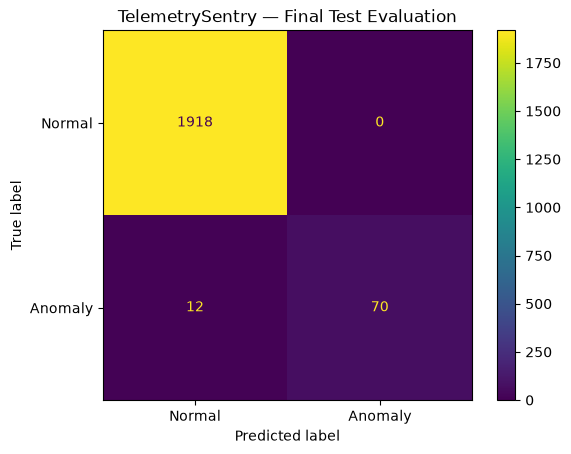

In [26]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

test_scores = hard_model.decision_function(X_test_hard)

y_test_pred = (test_scores < best_threshold).astype(int)

print(classification_report(
    y_test_hard,
    y_test_pred,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

cm = confusion_matrix(y_test_hard, y_test_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Anomaly"]
).plot()

plt.title("TelemetrySentry — Final Test Evaluation")
plt.show()

In [27]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

rule_test_pred = (
    (X_test_hard["request_duration_ms"] > 1000) |
    (X_test_hard["cpu_usage_pct"] > 85) |
    (X_test_hard["memory_usage_pct"] > 90) |
    (X_test_hard["error_rate_pct"] > 10) |
    (X_test_hard["requests_per_second"] > 250)
).astype(int)

def evaluate_model(name, actual, predicted):
    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    return {
        "Approach": name,
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1-score": f1_score(
            actual, predicted, zero_division=0
        ),
        "False positives": int(fp),
        "Missed anomalies": int(fn),
        "Detected anomalies": int(tp),
    }

comparison_hard = pd.DataFrame([
    evaluate_model(
        "Rule-based baseline",
        y_test_hard,
        rule_test_pred,
    ),
    evaluate_model(
        "Isolation Forest",
        y_test_hard,
        y_test_pred,
    ),
])

display(comparison_hard.round(3))

,Approach,Precision,Recall,F1-score,False positives,Missed anomalies,Detected anomalies
0,Rule-based baseline,1.0,0.854,0.921,0,12,70
1,Isolation Forest,1.0,0.854,0.921,0,12,70


## 15. Exporting Production Model Artifact
We serialize the trained Isolation Forest model, tuned threshold, and feature specification into a production joblib bundle. This artifact is loaded by the FastAPI service and Streamlit dashboard.

In [28]:
import joblib

artifact = {
    "model": hard_model,
    "threshold": best_threshold,
    "features": features,
}

joblib.dump(artifact, "models/telemetrysentry_model.joblib")

print("Model artifact saved successfully!")
print("Threshold:", best_threshold)
print("Features:", features)

Model artifact saved successfully!
Threshold: -0.11404003210920836
Features: ['request_duration_ms', 'cpu_usage_pct', 'memory_usage_pct', 'requests_per_second', 'error_rate_pct']
